# P1 EDA: FX returns, stationarity, first correlograms
Descriptive only. No config threshold is changed based on this notebook.

In [1]:
# 1. Imports, config, load pairs
# GOAL: load the daily FX prices, turn them into returns, and make a "squared returns" series.
import sys                       # lets us edit Python's module search path
from pathlib import Path         # object-style file paths
# The notebook lives in notebooks/, but our code lives in src/ one folder up.
# If the current folder has no src/, step up one level to find the project root.
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))    # put the project root first so "from src..." works

import numpy as np               # numbers / arrays
import pandas as pd              # tables and time series
import matplotlib.pyplot as plt  # plotting
from src.data import load_config, load_fx, to_log_returns            # our data helpers
from src.stat_tests import adf_kpss, ljung_box, arch_lm              # our statistical tests
from src.correlogram import acf_pacf_band, significant_lags         # our ACF/PACF helpers

cfg = load_config()              # read config.yaml into a dict (all settings live there)
prices = {}                      # will hold {series_id: price Series}
# Required pairs from config plus optional ones (DEXINUS); .get(...) returns [] if the key is missing.
for sid in list(cfg['pairs']) + list(cfg.get('pairs_optional', [])):
    try:
        # download-or-read-cache, keep dates from cfg['start']; cfg.get('end') is None = up to today
        prices[sid] = load_fx(sid, cfg['start'], cfg.get('end'), cfg)
    except Exception as e:       # if one series fails, report it and keep going
        print(f'{sid} failed: {e!r}')
# Log return x100 for each price series: r_t = 100 * ln(P_t / P_{t-1}), i.e. roughly "% change per day".
returns = {s: to_log_returns(p) for s, p in prices.items()}
# Squared DEMEANED returns: subtract the average return, then square. This is a simple proxy
# for each day's variance (how big the move was, ignoring direction). Volatility clustering
# (big moves follow big moves) shows up as autocorrelation in this series.
sq = {s: (r - r.mean()) ** 2 for s, r in returns.items()}
for s, p in prices.items():      # sanity print: sample size and date range per pair
    print(s, 'n =', len(p), '|', p.index.min().date(), 'to', p.index.max().date())

DEXUSEU n = 4191 | 2010-01-04 to 2026-10-02
DEXJPUS n = 4191 | 2010-01-04 to 2026-10-02
DEXINUS n = 4190 | 2010-01-04 to 2026-10-02


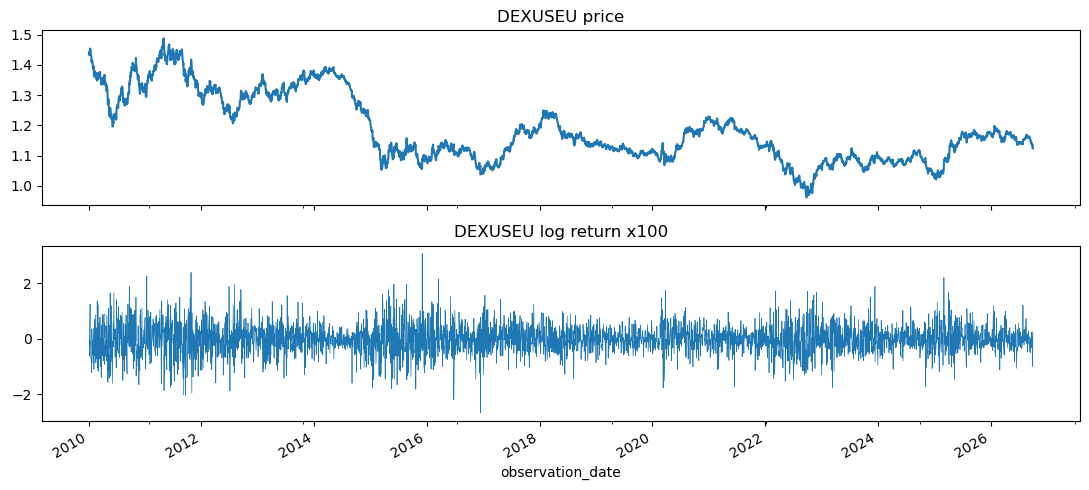

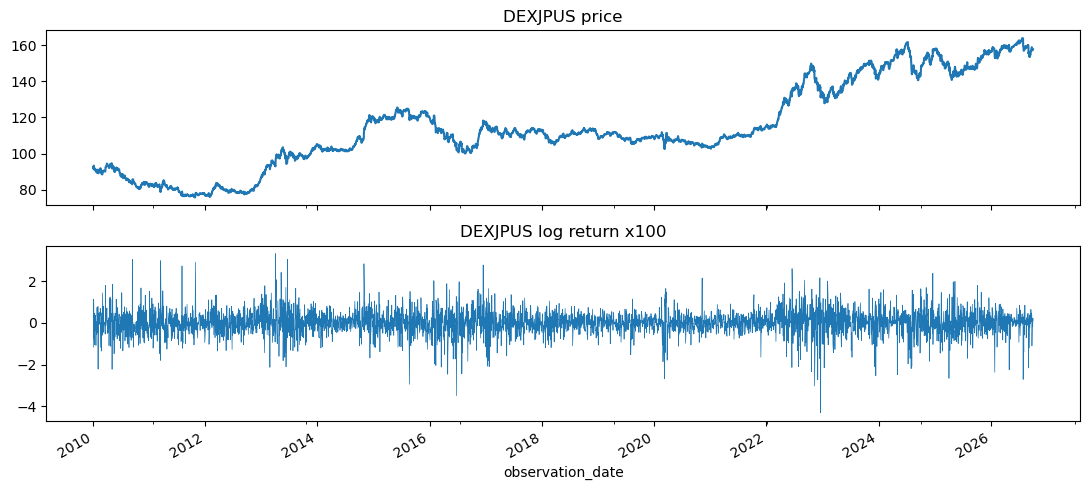

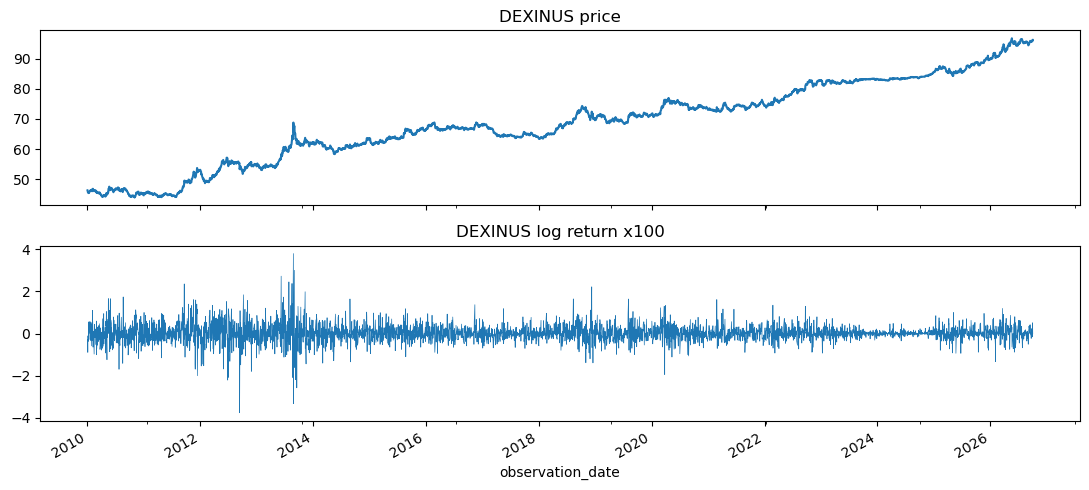

In [2]:
# 2. Price and return plots
# Prices wander (non-stationary); returns should bounce around 0 with calm and wild stretches.
for s in prices:
    fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)   # 2 stacked plots sharing the date axis
    prices[s].plot(ax=ax[0], title=f'{s} price')                 # top: price level
    returns[s].plot(ax=ax[1], lw=0.5, title=f'{s} log return x100')  # bottom: returns, thin line (lw=0.5)
    plt.tight_layout()           # stop titles/labels overlapping
    plt.show()                   # draw the figure

In [3]:
# 3. Descriptive stats (one row per pair)
# mean/std: centre and typical size of daily moves (std is the "volatility" in % per day)
# skew: asymmetry (0 = symmetric); excess kurtosis: tail fatness (0 = normal, >0 = fat tails)
# zero_returns: days with exactly no change (often stale quotes); min/max: biggest daily moves
desc = pd.DataFrame({
    s: {'mean': r.mean(), 'std': r.std(), 'skew': r.skew(), 'excess_kurtosis': r.kurt(),
        'zero_returns': int((r == 0).sum()),   # (r == 0) is True/False per day; sum() counts the Trues
        'min': r.min(), 'max': r.max()}
    for s, r in returns.items()
}).T                                           # .T flips so pairs are rows, stats are columns
desc                                           # last line of a cell is displayed automatically

,mean,std,skew,excess_kurtosis,zero_returns,min,max
DEXUSEU,-0.005904,0.517830,0.016406,1.837599,39.0,-2.672405,3.064268
DEXJPUS,0.012736,0.588912,-0.222989,4.217753,42.0,-4.322375,3.342812
DEXINUS,0.017500,0.421736,0.204683,8.748380,134.0,-3.755964,3.791923


In [4]:
# 4. ADF / KPSS stationarity tests on prices and on returns
# "Stationary" = mean and variance do not drift over time. Models like GARCH need that.
# ADF   : H0 = unit root (NOT stationary). Small p-value -> reject H0 -> evidence of stationarity.
# KPSS  : H0 = stationary.                Small p-value -> reject H0 -> evidence of NON-stationarity.
# They test opposite nulls, so we want ADF p small AND KPSS p large for "stationary".
# (KPSS p-values are looked up in a table, so they are capped: 0.1 means ">=0.1", 0.01 means "<=0.01".)
stat = {s: {'price': adf_kpss(prices[s]), 'returns': adf_kpss(returns[s])} for s in prices}
# Flatten {pair: {price/returns: result}} into a table with a (pair, series) row label.
pd.DataFrame({(s, k): v for s, d in stat.items() for k, v in d.items()}).T

/Users/arnav/fx-vol-acf-pacf/src/stat_tests.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p = adfuller(x, autolag="AIC")[:2]
/Users/arnav/fx-vol-acf-pacf/src/stat_tests.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p = adfuller(x, autolag="AIC")[:2]
/Users/arnav/fx-vol-acf-pacf/src/stat_tests.py:17: FutureWarning: adfuller current

adf_stat     adf_p kpss_stat kpss_p     verdict
DEXUSEU price    -2.536468  0.106851  6.006866   0.01   unit_root
        returns -63.377872       0.0  0.090348    0.1  stationary
DEXJPUS price    -0.326214  0.921709  8.019073   0.01   unit_root
        returns  -47.06972       0.0  0.104636    0.1  stationary
DEXINUS price     -0.04678  0.954488  9.652844   0.01   unit_root
        returns -15.998636       0.0   0.04587    0.1  stationary

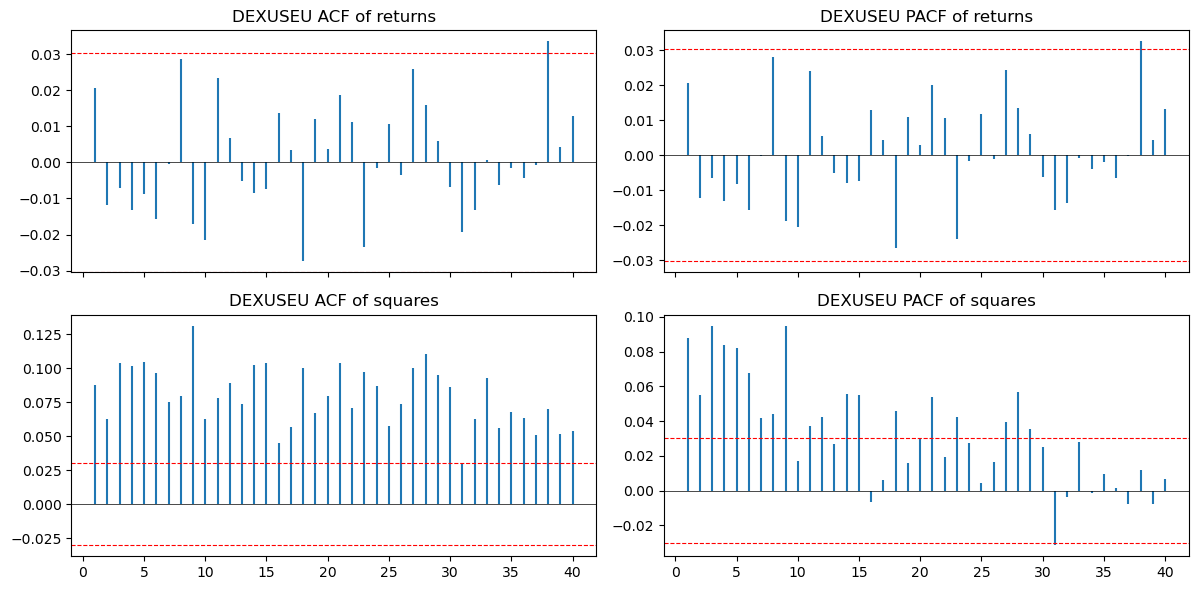

In [5]:
# 5. Four-panel ACF/PACF (first pair)
# ACF  = correlation of the series with itself k days earlier (lag k).
# PACF = same, but with the effect of lags 1..k-1 removed (the "direct" lag-k link).
# Red dashed lines = 95% band for "no autocorrelation": bars outside it are significant.
# Top row: returns (expect mostly inside the band = unpredictable direction).
# Bottom row: squared demeaned returns (bars outside the band = volatility clustering = GARCH-able).
nlags, conf = cfg['eda']['nlags'], cfg['band_confidence']   # how many lags / confidence level, from config
cor = {}                          # cache of ACF/PACF results per pair, reused in later cells

def four_panel(s):
    """Compute ACF/PACF for returns and squares of pair s, then plot a 2x2 grid."""
    cor[s] = {'returns': acf_pacf_band(returns[s], nlags, conf),   # dict with acf, pacf, band, n
              'squares': acf_pacf_band(sq[s], nlags, conf)}
    fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)   # 2 rows x 2 columns of plots
    lags = np.arange(1, nlags + 1)                                 # x-axis: lags 1..nlags
    for row, key in enumerate(['returns', 'squares']):             # row 0 = returns, row 1 = squares
        c = cor[s][key]
        for col, kind in enumerate(['acf', 'pacf']):               # column 0 = ACF, column 1 = PACF
            ax = axes[row, col]
            ax.vlines(lags, 0, c[kind])                            # one vertical bar per lag
            ax.axhline(0, color='k', lw=0.5)                       # zero line
            ax.axhline(c['band'], color='r', ls='--', lw=0.8)      # upper significance band
            ax.axhline(-c['band'], color='r', ls='--', lw=0.8)     # lower significance band
            ax.set_title(f'{s} {kind.upper()} of {key}')
    plt.tight_layout()
    plt.show()

first = next(iter(prices))        # first key in the dict = first pair that loaded
four_panel(first)

In [6]:
# 6. Significant lags, Ljung-Box, ARCH-LM (every pair)
# Ljung-Box: H0 = no autocorrelation up to lag L (tested jointly). Small p -> autocorrelation exists.
# ARCH-LM  : H0 = no ARCH effect (squared shocks not predictable from past squared shocks).
#            Small p -> volatility clustering exists -> a GARCH-type model makes sense.
diag = {}                         # results per pair, reused by the summary cell
for s in prices:
    if s not in cor:              # compute ACF/PACF if the plot cell has not done it already
        cor[s] = {'returns': acf_pacf_band(returns[s], nlags, conf),
                  'squares': acf_pacf_band(sq[s], nlags, conf)}
    c = cor[s]
    diag[s] = {
        # lags whose |ACF| is outside the band
        'sig_returns': significant_lags(c['returns']['acf'], c['returns']['band']),
        'sig_squares': significant_lags(c['squares']['acf'], c['squares']['band']),
        # joint test at lags from config (5, 10, 20), on returns and on squares
        'lb_returns': ljung_box(returns[s], cfg['gate']['lb_lags']),
        'lb_squares': ljung_box(sq[s], cfg['gate']['lb_lags']),
        # ARCH-LM with cfg['gate']['lm_lags'] lags (5)
        'arch_lm': arch_lm(returns[s], cfg['gate']['lm_lags']),
    }
    print('=====', s)
    print('significant ACF lags, returns:', diag[s]['sig_returns'])
    print('significant ACF lags, squared demeaned returns:', diag[s]['sig_squares'])
    print('Ljung-Box returns'); print(diag[s]['lb_returns'].to_string(index=False))
    print('Ljung-Box squared demeaned returns'); print(diag[s]['lb_squares'].to_string(index=False))
    print('ARCH-LM:', diag[s]['arch_lm'])

===== DEXUSEU
significant ACF lags, returns: [38]
significant ACF lags, squared demeaned returns: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 32, 33, 34, 35, 36, 37, 38, 39, 40]
Ljung-Box returns
 lag   lb_stat  lb_pvalue
   5  3.639470   0.602397
  10 11.313601   0.333613
  20 19.121043   0.513971
Ljung-Box squared demeaned returns
 lag    lb_stat     lb_pvalue
   5 183.541763  9.373735e-38
  10 362.967232  7.037689e-72
  20 645.256193 8.226259e-124
ARCH-LM: {'lm_stat': np.float64(139.52929058827579), 'lm_p': np.float64(2.2527873034578815e-28), 'f_stat': 28.82694980397948, 'f_p': 7.576343796751829e-29}
===== DEXJPUS
significant ACF lags, returns: [9, 26, 40]
significant ACF lags, squared demeaned returns: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 23, 24, 25, 26, 27, 28, 30, 33, 34, 35, 37, 39, 40]
Ljung-Box returns
 lag   lb_stat  lb_pvalue
   5  3.782949    0.58107
  10 13.872440    0.17

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning

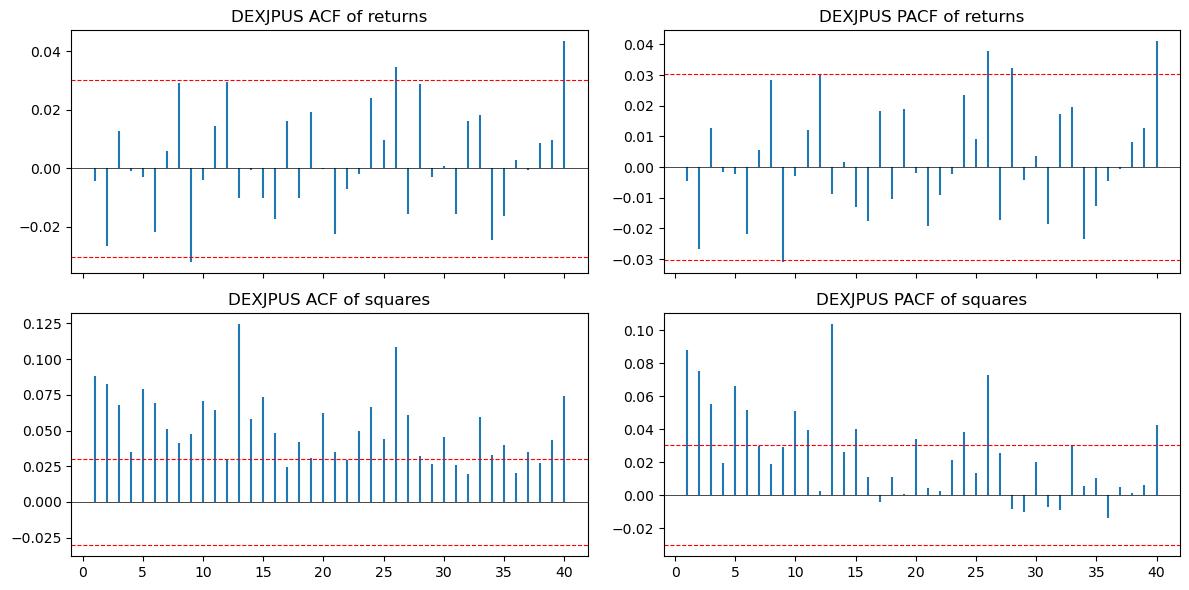

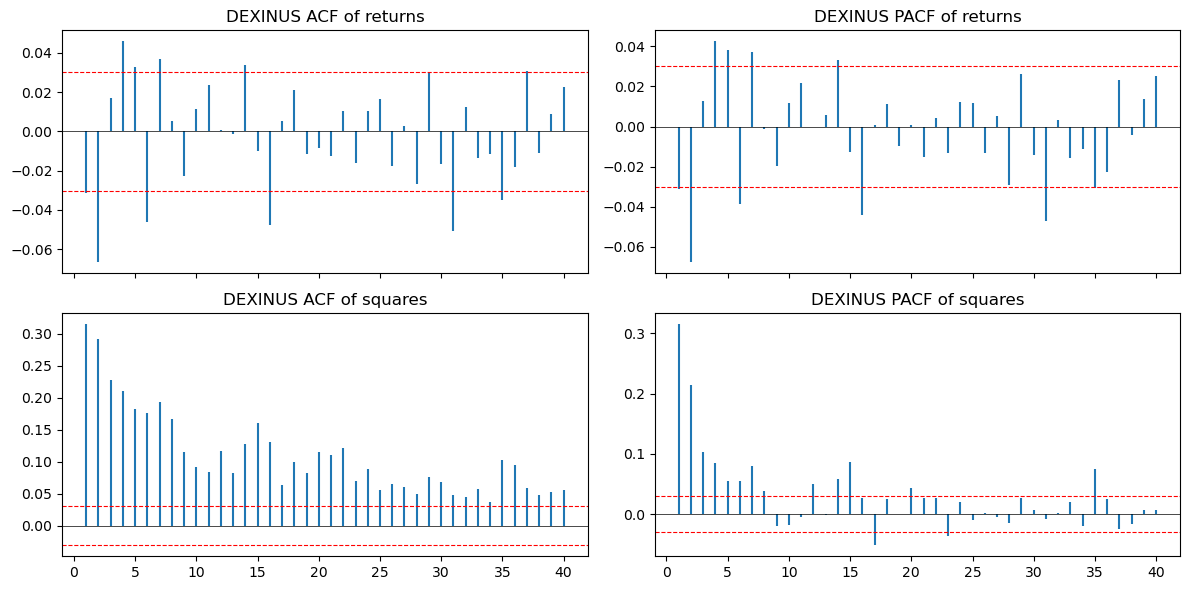

In [7]:
# 7. Four-panel plots for the remaining pairs
# list(prices)[1:] = every pair except the first (already plotted in step 5).
for s in list(prices)[1:]:
    four_panel(s)

In [8]:
# 8. Summary table: one row per pair, the key numbers side by side
lbk = cfg['arch_check']['lb_lags']      # Ljung-Box lag for the summary (10)
win = cfg['eda']['sig_window']          # count significant squared-return lags within 1..win (20)
rows = {}
for s in prices:
    a = stat[s]['returns']              # ADF/KPSS result for this pair's returns
    rows[s] = {
        'n': len(returns[s]),                                       # number of return observations
        'ADF_p_ret': a['adf_p'],                                    # small = stationary evidence
        'KPSS_p_ret': a['kpss_p'],                                  # large = stationary evidence
        'verdict': a['verdict'],                                    # combined ADF+KPSS call
        # [lbk] = a one-element list, .iloc[0] = take its only row's p-value
        f'LB({lbk})_p_ret': ljung_box(returns[s], [lbk])['lb_pvalue'].iloc[0],
        f'LB({lbk})_p_sq': ljung_box(sq[s], [lbk])['lb_pvalue'].iloc[0],
        f"ARCH-LM({cfg['gate']['lm_lags']})_p": diag[s]['arch_lm']['lm_p'],
        # sum() over booleans = how many significant lags are <= win
        f'sig_lags_1..{win}_sq': sum(l <= win for l in diag[s]['sig_squares']),
    }
summary = pd.DataFrame(rows).T          # rows = pairs
summary

,n,ADF_p_ret,KPSS_p_ret,verdict,LB(10)_p_ret,LB(10)_p_sq,ARCH-LM(5)_p,sig_lags_1..20_sq
DEXUSEU,4190,0.0,0.1,stationary,0.333613,0.0,0.0,20
DEXJPUS,4190,0.0,0.1,stationary,0.17889,0.0,0.0,19
DEXINUS,4189,0.0,0.1,stationary,0.0,0.0,0.0,20


## Gate decision (to fill after reading outputs)

Squared-return structure present (yes/no) per pair:

- 
